# Figure 5 — publication assembly

Rebuilds the assembled Figure 5 from the plot-ready pickles written by
`Figure5.ipynb` (`Figure5_helpers.run_all`). Nothing is recomputed here.
Panels are placed on a millimetre plan; `PAGE_H` is derived by summing the
vertical plan.

In [1]:
import os
import sys
import pickle

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.ticker
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

FIG5_DIR = '/project2/yangili1/cfbuenabadn/torino_paper/notebooks/Figure5'
ANALYSIS_DIR = '/project2/yangili1/cfbuenabadn/torino_paper/analysis'

os.chdir(ANALYSIS_DIR)
if FIG5_DIR not in sys.path:
    sys.path.append(FIG5_DIR)

import Figure5_plot_helpers as PH
import Figure5_examples as EX        # genotype_regression / TISSUE_MARKERS

DATA_DIR = os.path.join(FIG5_DIR, 'figure_data')

# The render cells below are module-level statements, so they would fire on
# `import Figure5_publication` and re-draw every page as a side effect. This is
# True when the file is run as a script or executed as notebook cells (where
# the module name is the main one), False when another module imports it.
# It is spelled this way rather than with the usual main-module test because
# nb_build.py splits the file on that exact line of source.
_IS_MAIN = __name__ != 'Figure5_publication'

## Panels and the choices behind them

Every panel is a pickle. Two things are not simply "the exploratory panel":

**Which isoforms E and G draw.** Not all four each gene has — only the ones
carrying the two factors plotted above them, read off the `factors` column of
the torino isoform bed:

| panel | factor to isoform | highlighted exon |
|---|---|---|
| E, *KNOP1* | factor_1 to isoform_1, factor_2 to isoform_2 | isoform_2 chr16:19,706,479-19,710,586, the retained intron |
| G, *CISD1* | factor_4 to isoform_2, factor_5 to isoform_4 | isoform_2 chr10:58,287,561-58,289,682, the long 3' exon |
| B, *PKFP* | isoform_1 = Annotated, isoform_2 = Torino | isoform_2 chr10:3,119,892-3,129,983, the retained intron |

These follow from the structures: *KNOP1* isoform_2 merges isoform_1's two
separate exons into one 4.1 kb block (that is the retention), and *CISD1*
isoform_2 and isoform_4 differ only in a 2121 bp versus 196 bp terminal exon.

**Region.** Panel F is labelled PCC, so E and F use the PCC coverage and
boxplot for `chr16:19708463:CTCA:C` (`knop1_pcc.pkl`, two plain RDS reads via
`prepare_publication_extras`). Panels G and H stay AC, as panel H's label says.
Panel B uses the PCC *PKFP* panel, matching panel C.

In [2]:
def load_panels(data_dir=DATA_DIR):
    """Every panel comes from a pickle; nothing is recomputed here."""
    def L(name):
        with open(os.path.join(data_dir, f'{name}.pkl'), 'rb') as f:
            return pickle.load(f)

    d = {n: L(n) for n in ['k3_beta_stats', 'pkfp_panels', 'ir_panel_k3',
                           'twas_panel', 'twas_panel_k3', 'coverage_panels',
                           'boxplot_panels', 'factor_panels', 'knop1_pcc',
                           # K=3 / pooled panels and the supplements
                           'knop1_factors_k3', 'knop1_box_pooled_k3',
                           'cisd1_box_pooled_k5', 'knop1_factors_k5_all',
                           'knop1_box_pooled_k5', 'cisd1_factors_k3_all',
                           'cisd1_box_pooled_k3', 'knop1_byad_pooled_k3',
                           'cisd1_byad_pooled_k3', 'ir_panel_k3_colocK3',
                           'k3_coloc_table']}
    return d


# ---- which isoform each panel draws, and which exon is the AD event ---------
#
# Panels E and G show only the isoforms carrying the two factors plotted above
# them, not all four the gene has. The mapping comes from the `factors` column
# of the torino isoform bed:
#
#   KNOP1  factor_1 -> isoform_1      factor_2 -> isoform_2
#   CISD1  factor_4 -> isoform_2      factor_5 -> isoform_4
#
# The highlighted exon is the AD event itself: the retained intron in KNOP1
# isoform_2 and the long 3' exon in CISD1 isoform_2 (which the risk allele
# shortens).
KNOP1 = {
    'gene': 'ENSG00000103550', 'name': 'KNOP1',
    'transcripts': ['ENSG00000103550.isoform_1', 'ENSG00000103550.isoform_2'],
    'highlight': {'ENSG00000103550.isoform_2': (19706479, 19710586)},
    'factor_labels': ['Factor 1', 'Factor 2'],
}
# The same gene on the gao_k3 bed: two isoforms rather than four, and the
# retained intron starts 3 bp later (19706482, not 19706479), so the highlight
# tuple has to match that bed's exon exactly.
KNOP1_K3 = {
    'gene': 'ENSG00000103550', 'name': 'KNOP1',
    'transcripts': ['ENSG00000103550.isoform_1', 'ENSG00000103550.isoform_2'],
    'highlight': {'ENSG00000103550.isoform_2': (19706482, 19710586)},
    'factor_labels': ['Factor 1', 'Factor 2'],
}
CISD1 = {
    'gene': 'ENSG00000122873', 'name': 'CISD1',
    'transcripts': ['ENSG00000122873.isoform_2', 'ENSG00000122873.isoform_4'],
    'highlight': {'ENSG00000122873.isoform_2': (58287561, 58289682)},
    'factor_labels': ['Factor 4', 'Factor 5'],
}
# PKFP: isoform_1 is the annotated model, isoform_2 the torino IR isoform whose
# 10 kb exon (3119892-3129983) is the retained intron.
PKFP = {
    'gene': 'ENSG00000067057', 'name': 'PKFP',
    'rows': [('Annotated', 'ENSG00000067057.isoform_1', None),
             ('Torino', 'ENSG00000067057.isoform_2', (3119892, 3129983))],
}
# Panel C shows five of the seven braak stages.
BRAAK_STAGES = [(0, 'stage 0\n(no tangle)'), (1, 'stage 1'), (4, 'stage 4'),
                (5, 'stage 5'), (6, 'stage 6\n(full invasion)')]

## Style and page plan

Nature Genetics double column (180 mm), 5.5-7 pt type, 0.5 pt rules,
`pdf.fonttype 42`. `rect()` turns a millimetre box on a top-left origin into
figure fractions, so later size requests are one-constant edits.

Colours differ from the exploratory panels: both factor tracks in E and G are a
single blue (the exploratory versions used the tab10 cycle for *KNOP1* and
red+purple for *CISD1*), isoform models are navy with the AD event exon in red,
and genotype coverage keeps darkred / orangered / gold.

In [3]:
matplotlib.rcParams.update({
    # pdf.fonttype 42 embeds the font as a Type0/CIDFontType2 subset with
    # Identity-H encoding, so the PDF stores glyph *ids*, not characters. Text
    # extracts correctly (there is a ToUnicode map) but Inkscape cannot re-lay
    # it out, which is why editing a label there stacks every letter on one
    # spot. svg.fonttype 'none' keeps text as plain <text> with a font-family
    # name and no embedded glyphs, so the SVG export is the editable one.
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
    'font.family': 'sans-serif', 'font.sans-serif': ['DejaVu Sans'],
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'xtick.major.size': 2, 'ytick.major.size': 2, 'font.size': 6,
})

FS_TICK = 5.5      # tick labels
FS_ANNOT = 5.5     # in-panel annotation
FS_LAB = 6.0       # axis labels
FS_TITLE = 7.0     # panel titles
FS_PANEL = 9       # panel letters
LW = 0.6

NAVY, RED = 'midnightblue', '#d62728'
# One colour per factor track, chosen so each track matches the boxplot drawn
# from that same factor: E factor 2 -> F (orange), G factor 4 -> H (blue).
FACTOR_COLORS = {'ENSG00000103550.factors': ['tab:blue', 'tab:orange'],
                 'ENSG00000122873.factors': ['tab:blue', 'tab:orange']}
BOX_COLORS = {'F': 'tab:orange', 'H': 'tab:blue'}
MS_TWAS = 4.0 * 1.2 ** 2       # panel D, 120% of the previous marker diameter
MS_STRIP = 1.3 * 2             # panels F and H, twice the previous diameter
GENO_COLORS = ['darkred', 'orangered', 'gold']  # ref/ref, ref/alt, alt/alt
AD_RED, CTRL_GREY = 'tab:red', 'tab:gray'

# ---- page plan (mm, top-left origin) ---------------------------------------
PAGE_W = 180.0                 # Nature Genetics double column

M_TOP, M_BOT = 6.0, 8.0
LX = 11.0                      # left column origin

# row 1: A (narrow bars) + B (PKFP coverage)
# A holds 2 bars at the width they had as 3: one x-unit is 22.0/3.5 = 6.286 mm,
# and 2 slots plus the same 0.75-unit margins is 2.5 units -> 15.7 mm.
A_X, A_W, A_H = LX, 15.7, 30.0
B_X, B_W, B_H = 43.7, 118.3, 32.0   # takes the 6.3 mm A gave up; right edge unchanged

# row 2: C (IR progression) + D (TWAS)
# C is 130% of its previous 84 x 48 mm; D moves right and narrows to fit
C_X, C_W, C_H = 6.0, 106.0, 62.0
D_X, D_W, D_H = 130.0, 44.0, 62.0

# rows 3 and 4: locus panels (E/G) + their boxplots (F/H)
LOC_X, LOC_W = LX, 92.0
BOX_X, BOX_W, BOX_H = 120.0, 42.0, 31.0
COV_H = 20.0                   # coverage track in E / G
TRACK_H = 6.5                  # one factor track
IROW_H = 2.0                   # one isoform row
IROW_GAP = 0.6
LOC_H = COV_H + 2 * TRACK_H + 2 * (IROW_H + IROW_GAP)

GAP_12, GAP_23, GAP_34 = 14.0, 12.0, 10.0

# vertical plan, summed top-down
Y_ROW1 = M_TOP
Y_ROW2 = Y_ROW1 + max(A_H, B_H) + GAP_12
Y_ROW3 = Y_ROW2 + max(C_H, D_H) + GAP_23
Y_ROW4 = Y_ROW3 + LOC_H + GAP_34
PAGE_H = Y_ROW4 + LOC_H + M_BOT          # derived, not typed


def rect(x, y, w, h):
    """mm box with a top-left origin -> matplotlib [left, bottom, w, h]."""
    return [x / PAGE_W, 1.0 - (y + h) / PAGE_H, w / PAGE_W, h / PAGE_H]


def panel_letter(fig, x, y, letter, page_w=None, page_h=None):
    """
    Panel letter at (x, y) mm from the top-left of the page.

    `page_w` / `page_h` default to the main figure's page. The supplements are
    a different size, so they must pass their own — otherwise the letters are
    placed against the wrong height and drift up the page.
    """
    fig.text(x / (page_w or PAGE_W), 1.0 - y / (page_h or PAGE_H), letter,
             fontsize=FS_PANEL, fontweight='bold', va='top', ha='left')


def _mirror(v, anchor):
    """Reflect a coordinate into the minus-strand drawing space."""
    return anchor[0] + anchor[1] - v

## Panel drawing

Each function takes plot-ready data and an axes. Two notes:

* **Panel C** puts every segment into one rasterised `LineCollection` per column
  (two per column: exons+ticks and introns). Drawn as individual rasterised
  lines it makes ~100k rasterised groups, and `savefig(pdf)` then allocates a
  full-figure raster buffer per group and is OOM-killed with no traceback.
* **Panel C** also re-solves the gene-label placement for this panel's height;
  the placements cached in the pickle were solved for the much taller
  single-stage figure and collide at 43 mm.

In [4]:
def draw_beta_percentage(ax, stats):
    """
    A — percentage of significant factors increasing in AD.

    Source: gao_k3/beta_percentage_allIR (AD_K3_RetainedIntrons.ipynb cell 68),
    relabelled for the figure.
    """
    # the grey "all significant" bar is dropped, so the ** bracket that spanned
    # it goes too; only the No-IR vs IR comparison remains
    vals = [stats['si_pos_ratio'], stats['ir_pos_ratio']]
    ax.bar(range(1, 3), vals, color=['tab:blue', 'tab:red'], width=0.75, linewidth=0)
    ax.plot([1, 1], [vals[0] + 0.02, 1.03], c='gray', linewidth=LW)
    ax.plot([1, 2], [1.03, 1.03], c='gray', linewidth=LW)
    ax.plot([2, 2], [1.03, vals[1] + 0.01], c='gray', linewidth=LW)
    ax.text(1.5, 1.04, '***', size=FS_ANNOT, ha='center')
    ax.set_xlim((0.25, 2.75))
    ax.set_ylim((0, 1.15))
    ax.set_xticks([])
    ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1])
    ax.set_yticklabels(['20', '40', '60', '80', '100'], fontsize=FS_TICK)
    ax.spines['left'].set_bounds(0, 1)
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_ylabel('Percentage increasing in AD', fontsize=FS_LAB)
    ax.set_xlabel('Genes with IR', fontsize=FS_LAB)
    ax.set_title('Significant factors', fontsize=FS_ANNOT, pad=3)
    for i, lab in enumerate(['No IR (29.6%)', 'IR (98.2%)']):
        ax.text(i + 1 - 0.14, 0.04, lab, rotation=90, size=4.6, va='bottom')


def draw_isoform_rows(axes, iso_gene, transcripts, strand, anchor, xlim,
                      highlight=None, lw=1.1):
    """
    One isoform track per axes, drawing only `transcripts`.

    `anchor` is computed from *all* of the gene's isoforms, matching what
    GeneticsPlots.plot_isoform_annotations would use, so the minus-strand
    mirroring stays aligned with the factor tracks above.
    """
    highlight = highlight or {}
    for ax, t in zip(axes, transcripts):
        ex = iso_gene.loc[iso_gene.transcript_id == t].sort_values('start')
        hl = highlight.get(t)
        drawn = []
        for _, r in ex.iterrows():
            s, e = int(r.start), int(r.end)
            red = hl is not None and s == hl[0] and e == hl[1]
            drawn.append(((_mirror(e, anchor), _mirror(s, anchor)) if strand == '-'
                          else (s, e)) + (red,))
        lo = min(s for s, _, _ in drawn)
        hi = max(e for _, e, _ in drawn)
        ax.plot([lo, hi], [0.5, 0.5], color=NAVY, linewidth=lw,
                solid_capstyle='butt')
        for s, e, red in drawn:
            ax.fill_between([s, e], [0, 0], [1, 1], color=RED if red else NAVY,
                            linewidth=0, zorder=3)
        ax.set_xlim(xlim)
        ax.set_ylim(0, 1)
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)


def draw_coverage(ax, cov, strand, xlim, smooth=100, colors=None, labels=None,
                  legend_loc='upper right', legend_title=None):
    """
    Genotype- or condition-stratified coverage, reproducing the smoothing and
    minus-strand mirroring of GeneticsPlots.plot_coverage.
    """
    colors = colors or GENO_COLORS
    c = cov['coverage_dir']
    coords = list(c['coords'])
    refs, hets, alts = (list(c['ref_coverage']), list(c['het_coverage']),
                        list(c['alt_coverage']))
    sc = np.array([np.mean(coords[i:i + smooth]) for i in range(len(coords))]) - smooth
    sa = [np.mean(alts[i:i + smooth]) for i in range(len(alts))]
    sh = [np.mean(hets[i:i + smooth]) for i in range(len(hets))]
    sr = [np.mean(refs[i:i + smooth]) for i in range(len(refs))]
    ref, alt = c['ref_allele'], c['alt_allele']
    var_pos = c['var_pos']
    if strand == '-':
        sa, sh, sr = sa[::-1], sh[::-1], sr[::-1]
        var_pos = sc[-1] + sc[0] - var_pos

    lab = labels or [f'{alt}/{alt}', f'{ref}/{alt}', f'{ref}/{ref}']
    ax.plot(sc, sa, label=lab[0], c=colors[2], linewidth=LW)
    ax.plot(sc, sh, label=lab[1], c=colors[1], linewidth=LW)
    ax.plot(sc, sr, label=lab[2], c=colors[0], linewidth=LW)

    top = np.nanmax([np.nanmax(sa), np.nanmax(sh), np.nanmax(sr)])
    ax.plot([var_pos, var_pos], [0, top], linestyle='--', c='black', linewidth=LW)
    ax.set_xlim(xlim)
    ax.set_ylim(-0.02 * top, top * 1.12)
    ax.set_xticks([])
    ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(nbins=3, integer=True,
                                                             steps=[1, 2, 5, 10]))
    ax.set_ylabel('normalized counts', fontsize=FS_LAB)
    ax.tick_params(labelsize=FS_TICK)
    ax.spines[['top', 'right', 'bottom']].set_visible(False)
    ax.legend(frameon=False, fontsize=FS_ANNOT, loc=legend_loc, handlelength=1.1,
              borderpad=0.1, labelspacing=0.2, title=legend_title,
              title_fontsize=FS_ANNOT)
    return var_pos


def draw_locus(fig, y, cov_panel, fac_panel, spec, snp_label, title,
               legend_loc='upper right', star=None, snp_ha='center',
               factor_colors=None, legend_title=None, lm=False):
    """
    E / G — genotype coverage, the two factors, and the isoform models.

    The factor tracks are drawn by the same code path as the exploratory panels
    (Figure5_plot_helpers.plot_factors_wrapper) so the detrending is identical;
    only the axes plumbing and the colours differ. Both tracks use one blue,
    where the exploratory versions used the tab10 cycle / red+purple.
    """
    strand = fac_panel['strand']
    xc = fac_panel['xlim_coords']
    xlim = (xc[0] - 1000, xc[-1] + 1000)

    ax_cov = fig.add_axes(rect(LOC_X, y, LOC_W, COV_H))
    var_pos = draw_coverage(ax_cov, cov_panel, strand, xlim,
                            legend_loc=legend_loc, legend_title=legend_title)
    ax_cov.set_title(title, fontsize=FS_TITLE, pad=3)
    ax_cov.text(var_pos, ax_cov.get_ylim()[1] * 0.99, snp_label, fontsize=FS_ANNOT,
                ha=snp_ha, va='top')

    f_axes = [fig.add_axes(rect(LOC_X, y + COV_H + i * TRACK_H, LOC_W, TRACK_H))
              for i in range(2)]
    # lm=False: the factor tracks are the raw smoothed factors. The lm
    # correction (Figure5_plot_helpers.factor_lm) divides each factor by a
    # line fitted along the gene when that line's slope runs with the strand,
    # to flatten 3' coverage decay. It reshapes the tracks, so it is off here.
    PH.plot_factors_wrapper(fac_panel['EF_smooth'], fac_panel['coords'],
                            spec['name'], factor_list=fac_panel['factor_list'],
                            xlim=xlim, mute_y_axis=True, ax=f_axes, strand=strand,
                            colores=factor_colors, lwidth=LW, lm=lm)
    for ax, lab in zip(f_axes, spec['factor_labels']):
        ax.set_xticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        ax.text(-0.008, 0.5, lab, transform=ax.transAxes, fontsize=FS_ANNOT,
                ha='right', va='center')
    if star is not None:
        f_axes[1].text(star[0], star[1], '* tandem repeat',
                       transform=f_axes[1].transAxes, fontsize=FS_ANNOT,
                       ha='left', va='center')

    # Exon models come from the factor panel's isoform bed, not the coverage
    # panel's: they are mirrored about the factorisation's coordinates, so they
    # must be the bed that factorisation was built on. The two are the same bed
    # for a K=5 panel, but a K=3 factor panel pairs with gao_k3, which has
    # different isoforms and exon bounds (KNOP1: 2 isoforms, retained intron at
    # 19706482 rather than 19706479).
    iso_src = fac_panel.get('iso', cov_panel['iso'])
    iso_gene = iso_src.loc[iso_src.gene_id == spec['gene']]
    # Pin the isoform mirroring to the SAME coordinates the factor tracks are
    # mirrored about (rds['filtered_coords']). Deriving it from the isoform bed
    # instead -- what GeneticsPlots does by default -- makes minus-strand exons
    # slide by however far that bed's gene extent differs: 49 bp with the gao
    # bed, 1403 bp with gao_k3, while xlim stays identical either way.
    fc = [int(c.split(':')[1]) for c in fac_panel['coords']]
    anchor = (min(fc), max(fc))
    y0 = y + COV_H + 2 * TRACK_H
    i_axes = [fig.add_axes(rect(LOC_X, y0 + i * (IROW_H + IROW_GAP), LOC_W, IROW_H))
              for i in range(len(spec['transcripts']))]
    draw_isoform_rows(i_axes, iso_gene, spec['transcripts'], strand, anchor, xlim,
                      highlight=spec['highlight'])
    i_axes[0].text(-0.008, 0.5, spec['name'], transform=i_axes[0].transAxes,
                   fontsize=FS_ANNOT, ha='right', va='center', style='italic')


def draw_pkfp(fig, y, panel):
    """
    B — mean normalised PKFP coverage, AD (braak 6) vs control (braak 0), with
    the annotated model and the torino IR isoform below.

    Source: gao_k3/PKFP_PCC_counts. The retained intron of isoform_2 is drawn
    red; the exploratory version drew every exon navy.
    """
    coords_, df1, df2 = panel['coords_'], panel['df1'], panel['df2']
    xlim = (3066503 - 4000, 3137800 + 3700)

    ax = fig.add_axes(rect(B_X, y, B_W, B_H - 8.0))
    ax.plot(coords_, np.array(df1.rolling(150,).mean().T.iloc[0]), color=AD_RED,
            label='AD (Braak 6)', linewidth=LW)
    ax.plot(coords_, np.array(df2.rolling(150,).mean().T.iloc[0]), color=CTRL_GREY,
            label='Controls (Braak 0)', linewidth=LW)
    ax.legend(frameon=False, fontsize=FS_ANNOT, loc='upper left', handlelength=1.2,
              borderpad=0.1, labelspacing=0.25)
    ax.set_xlim(xlim)
    ax.set_xticks([])
    ax.set_ylabel('Mean normalized counts', fontsize=FS_LAB)
    ax.tick_params(labelsize=FS_TICK)
    ax.ticklabel_format(axis='y', style='plain')
    ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%.5f'))
    ax.spines[['top', 'right', 'bottom']].set_visible(False)
    ax.set_title('Novel intron retention isoform in $\\it{PFKP}$ increases in AD samples.',
                 fontsize=FS_TITLE, pad=3)

    se = panel['snmf_exons']
    strand = se.strand.iloc[0]
    anchor = (int(se.start.min()) - 1000, int(se.end.max()) + 1000)
    y0 = y + B_H - 8.0
    for i, (label, tid, hl) in enumerate(PKFP['rows']):
        ax_i = fig.add_axes(rect(B_X, y0 + i * (IROW_H + IROW_GAP), B_W, IROW_H))
        draw_isoform_rows([ax_i], se, [tid], strand, anchor, xlim,
                          highlight=({tid: hl} if hl else None))
        ax_i.text(1.006, 0.5, label, transform=ax_i.transAxes, fontsize=FS_ANNOT,
                  ha='left', va='center')
    fig.text((B_X - 1.0) / PAGE_W, 1.0 - (y0 + IROW_H / 2) / PAGE_H, PKFP['name'],
             fontsize=FS_ANNOT, ha='right', va='center', style='italic')


def draw_ir_progression(fig, y, panel, stages=BRAAK_STAGES):
    """
    C — one gene-body IR heatmap per braak stage, sharing a colour bar.

    Source: gao_k3/IR_only_progression_labeled.PCC.{i}. The exploratory figures
    draw one stage per file with its own labels and colour bar; here the gene
    labels sit once on the left and the colour bar once on the right.
    """
    order_df = panel['order_df']
    introns_bed = panel['introns_bed']
    gencode_beds = panel['gencode_beds']
    gene_names = panel['gene_names']
    gene_label = panel['gene_label']
    colores = sns.color_palette("vlag", 10)
    # ~2.2 mm of label height expressed in row units for this panel's height
    n_genes = sum(1 for g in order_df.gene if g in gencode_beds)
    min_gap = 2.2 / (C_H - 5.0) * n_genes
    placements = PH.place_labels(order_df, gene_label, min_gap=min_gap)

    lab_w, cb_w, gap = 13.0, 4.0, 1.2
    col_w = (C_W - lab_w - cb_w - gap * len(stages)) / len(stages)

    ax_lab = fig.add_axes(rect(C_X, y + 5.0, lab_w, C_H - 5.0))
    axes = [fig.add_axes(rect(C_X + lab_w + k * (col_w + gap), y + 5.0, col_w,
                              C_H - 5.0)) for k in range(len(stages))]

    # rows are shared across stages; draw the gene models once per column.
    #
    # Every segment goes into ONE rasterised LineCollection per column (two:
    # exons+ticks and introns). Drawing them as individual rasterised lines
    # makes ~100k rasterised groups, and savefig(pdf) then allocates a
    # full-figure raster buffer per group and is OOM-killed with no traceback --
    # the same trap as Figure1 panel C.
    from matplotlib.collections import LineCollection

    rows = list(order_df.sort_values('position').iterrows())
    n_rows = 0
    for k, (stage, title) in enumerate(stages):
        ax = axes[k]
        seg_black, seg_intron, col_intron = [], [], []
        pos = 0
        score_col = f'braaks_{stage}_zloadings.PCC'
        for _, row in rows:
            gene, strand = row.gene, row.strand
            gb = gencode_beds.get(gene)
            if gb is None:
                continue
            start_, end_ = gb.end.iloc[0], gb.start.iloc[-1]
            seg_black.append([(-0.02, pos), (0.0, pos)])
            seg_black.append([(1.0, pos), (1.02, pos)])
            if gb.shape[0] >= 3:
                for _, exon in gb.iloc[1:-1].iterrows():
                    a = (exon.start - start_) / (end_ - start_)
                    b = (exon.end - start_) / (end_ - start_)
                    if strand == '-':
                        a, b = 1 - a, 1 - b
                    seg_black.append([(a, pos), (b, pos)])
            for _, intron in introns_bed.loc[introns_bed.gene == gene].iterrows():
                a = (intron.start - start_) / (end_ - start_)
                b = (intron.end - start_) / (end_ - start_)
                if strand == '-':
                    a, b = 1 - a, 1 - b
                seg_intron.append([(a, pos), (b, pos)])
                col_intron.append(PH.select_color(intron[score_col], colores))
            pos -= 1
        n_rows = -pos
        ax.add_collection(LineCollection(seg_black, colors='black', linewidths=0.25,
                                         rasterized=True))
        ax.add_collection(LineCollection(seg_intron, colors=col_intron,
                                         linewidths=0.25, rasterized=True))
        ax.set_title(title, size=FS_ANNOT, pad=2, linespacing=1.2)
        ax.set_xlim(-0.05, 1.05)
        ax.set_ylim(-n_rows, 1)
        ax.set_xticks([-0.02, 1.02])
        ax.set_xticklabels(['TSS', 'TES'] if k == 0 else ['', ''],
                           size=FS_ANNOT, rotation=45, ha='right')
        ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)

    ylim = axes[0].get_ylim()
    for ax in axes:
        ax.set_ylim(ylim)

    # gene labels, once, against the first column
    ax_lab.set_ylim(ylim)
    ax_lab.set_xlim(-1, 0)
    ax_lab.set_xticks([]); ax_lab.set_yticks([])
    for sp in ax_lab.spines.values():
        sp.set_visible(False)
    pos = 0
    for _, row in order_df.sort_values('position').iterrows():
        col = gene_label.get(row.gene)
        if col is not None and row.gene in placements:
            ly = placements[row.gene]
            ax_lab.plot([-0.30, -0.02], [ly, pos], c=col, linewidth=0.4)
            ax_lab.text(-0.33, ly, gene_names[row.gene], c=col, size=FS_ANNOT,
                        ha='right', va='center', style='italic')
        pos -= 1

    cax = fig.add_axes(rect(C_X + C_W - cb_w + 1.0, y + 12.0, 1.6, C_H - 24.0))
    cmap = ListedColormap(colores)
    norm = BoundaryNorm(PH.BOUNDS_WIDE, cmap.N)
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax,
                      boundaries=PH.BOUNDS_WIDE)
    cb.set_label('Intron retention z-score', fontsize=FS_LAB)
    cb.ax.tick_params(labelsize=FS_TICK)

    fig.text((C_X + lab_w + (C_W - lab_w - cb_w) / 2) / PAGE_W,
             1.0 - (y - 3.0) / PAGE_H,
             'Intron retention levels increase with AD\nprogression in PCC (Braak stage)',
             fontsize=FS_TITLE, ha='center', va='bottom', linespacing=1.25)
    fig.text((C_X + lab_w - 1.0) / PAGE_W, 1.0 - (y + 3.6) / PAGE_H, 'Braak',
             fontsize=FS_ANNOT, ha='right', va='center')


def draw_twas(ax, panel):
    """
    D — TWAS of isoform loadings with AD.

    Source: TWAS_summary (Figure5_summary_plots.ipynb cell 41), drawn into a
    supplied axes.
    """
    import matplotlib.lines as mlines
    df = panel['df_significant']
    coloc, mr = panel['coloc_phenotypes'], panel['mr_phenotypes']
    names = panel['gene_names']
    grp = df.groupby('molecular_id')
    i, glist, ilist = 0, [], []
    for gene, pval in grp.twas_pval.min().sort_values().items():
        gdf = grp.get_group(gene)
        ax.plot([0, -np.log10(pval)], [i, i], c='tab:gray', zorder=1, linewidth=0.4)
        for pheno, p_ in gdf.loc[gdf.passes_cutoff].groupby('phenotype').twas_pval.min().items():
            # s is an area, so 120% of the marker *diameter* is 1.2**2 in s
            ax.scatter([-np.log10(p_)], [i], zorder=2, alpha=0.75,
                       s=MS_TWAS, linewidth=0,
                       c='tab:red' if pheno in coloc else 'tab:blue',
                       marker='^' if pheno in mr else 'o')
        glist.append(names[gene]); ilist.append(i); i -= 1
    ax.set_yticks(ilist)
    ax.set_yticklabels(glist, fontsize=2.9, style='italic')
    ax.tick_params(axis='y', length=0, pad=1)
    ax.tick_params(axis='x', labelsize=FS_TICK)
    ax.set_xlabel(r'$-log_{10}(p)$', fontsize=FS_LAB)
    ax.set_ylim([i, 1])
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_title('TWAS of isoform loadings with AD', fontsize=FS_TITLE, pad=3)

    col = [mlines.Line2D([], [], color=c, marker='o', linestyle='None',
                         markersize=2.5, label=l)
           for c, l in [('tab:red', 'Colocalized'), ('tab:blue', 'Not colocalized')]]
    shp = [mlines.Line2D([], [], color='k', marker=m, linestyle='None',
                         markersize=2.5, label=l)
           for m, l in [('^', 'Significant'), ('o', 'Not significant')]]
    lg1 = ax.legend(handles=shp, title='Mendelian Randomization', loc='center right',
                    fontsize=4.2, title_fontsize=4.2, frameon=False,
                    borderpad=0.1, labelspacing=0.2, handletextpad=0.4)
    ax.add_artist(lg1)
    ax.legend(handles=col, title='Colocalization', loc='lower right', fontsize=4.2,
              title_fontsize=4.2, frameon=False, borderpad=0.1, labelspacing=0.2,
              handletextpad=0.4)


def draw_boxplot(ax, df, factor, ylabel, xlabel, color, order=None):
    """F / H — factor loadings by genotype."""
    sns.boxplot(data=df, x='genotype', y=factor, width=.55, fliersize=0,
                linewidth=LW, patch_artist=True, ax=ax, hue='genotype',
                legend=False, order=order, hue_order=order,
                boxprops=dict(edgecolor=color, facecolor='white'),
                whiskerprops=dict(color=color, linewidth=LW),
                capprops=dict(color=color, linewidth=LW),
                medianprops=dict(color=color, linewidth=LW))
    sns.stripplot(data=df, x='genotype', y=factor, c=color, alpha=0.4, ax=ax,
                  size=MS_STRIP, jitter=0.22, order=order, rasterized=True)
    # sample size per genotype, in the plotted order
    n = df.genotype.value_counts()
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f'{g}\n(n={int(n.get(g, 0))})' for g in order],
                       fontsize=FS_TICK)
    ax.set_ylabel(ylabel, fontsize=FS_LAB, linespacing=1.4)
    ax.set_xlabel(xlabel, fontsize=FS_LAB)
    ax.tick_params(labelsize=FS_TICK)
    ax.spines[['top', 'right']].set_visible(False)


def draw_pooled_boxplot(ax, df, factor, ylabel, xlabel, color, order,
                        markers=None, regression=True, reg_covariates=('tissue',),
                        reg_loc='upper left', legend_loc='lower right',
                        legend=True, ms=MS_STRIP, seed=0):
    """
    F / H — one factor's loadings by genotype, pooling AC, PCC and DLPFC.

    The boxes summarise all three tissues; the marker keeps each point
    attributable (AC '+', PCC 'x', DLPFC '^'). Points are scattered directly
    rather than through sns.stripplot, which drops the stroke of '+' and 'x'
    and would draw only the filled marker — see Figure5_examples.

    `regression` writes beta and the p-value of `factor ~ allele dosage`, fitted
    with tissue as a covariate so a difference in mean loading between tissues
    cannot pass as a genotype effect. Dosage counts steps along `order`.
    """
    markers = markers or EX.TISSUE_MARKERS
    sns.boxplot(data=df, x='genotype', y=factor, width=.55, fliersize=0,
                linewidth=LW, patch_artist=True, ax=ax, hue='genotype',
                legend=False, order=order, hue_order=order,
                boxprops=dict(edgecolor=color, facecolor='white'),
                whiskerprops=dict(color=color, linewidth=LW),
                capprops=dict(color=color, linewidth=LW),
                medianprops=dict(color=color, linewidth=LW))

    pos = {g: i for i, g in enumerate(order)}
    rng = np.random.default_rng(seed)
    stroke = ('+', 'x', '1', '2', '3', '4', '|', '_')
    for tissue in [t for t in markers if t in set(df.tissue)]:
        ts = df.loc[df.tissue == tissue]
        x = ts.genotype.map(pos).to_numpy(dtype=float)
        keep = ~np.isnan(x)
        x = x[keep] + rng.uniform(-0.22, 0.22, size=int(keep.sum()))
        m = markers[tissue]
        ax.scatter(x, ts[factor].to_numpy(dtype=float)[keep], marker=m,
                   s=ms ** 2, alpha=0.45, linewidths=0.35, zorder=3,
                   **({'color': color} if m in stroke
                      else {'facecolors': 'none', 'edgecolors': color}))

    n = df.genotype.value_counts()
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f'{g}\n(n={int(n.get(g, 0))})' for g in order],
                       fontsize=FS_TICK)
    ax.set_ylabel(ylabel, fontsize=FS_LAB, linespacing=1.4)
    ax.set_xlabel(xlabel, fontsize=FS_LAB)
    ax.tick_params(labelsize=FS_TICK)
    ax.spines[['top', 'right']].set_visible(False)

    ax.regression_ = None
    if regression:
        ax.regression_ = EX.genotype_regression(df, factor, order,
                                                list(reg_covariates or []))
        if str(reg_loc).startswith('upper'):
            lo, hi = ax.get_ylim()
            ax.set_ylim(lo, hi + 0.16 * (hi - lo))
        EX.annotate_regression(ax, ax.regression_, loc=reg_loc,
                               fontsize=FS_ANNOT, color=color)

    ax.tissue_handles_ = handles = [
        plt.Line2D([], [], linestyle='None', marker=markers[t], color='k',
        markerfacecolor=('k' if markers[t] in stroke else 'none'),
        markeredgecolor='k', markeredgewidth=0.35, markersize=ms * 1.2,
        label=f'{t} ({int(df.tissue.value_counts().get(t, 0))})')
        for t in markers if t in set(df.tissue)]
    if legend:
        ax.legend(handles=handles, frameon=False, fontsize=FS_ANNOT,
                  loc=legend_loc, handletextpad=0.3, borderpad=0.1,
                  labelspacing=0.2)
    return ax

## Assembly

page: 180.0 x 220.4 mm


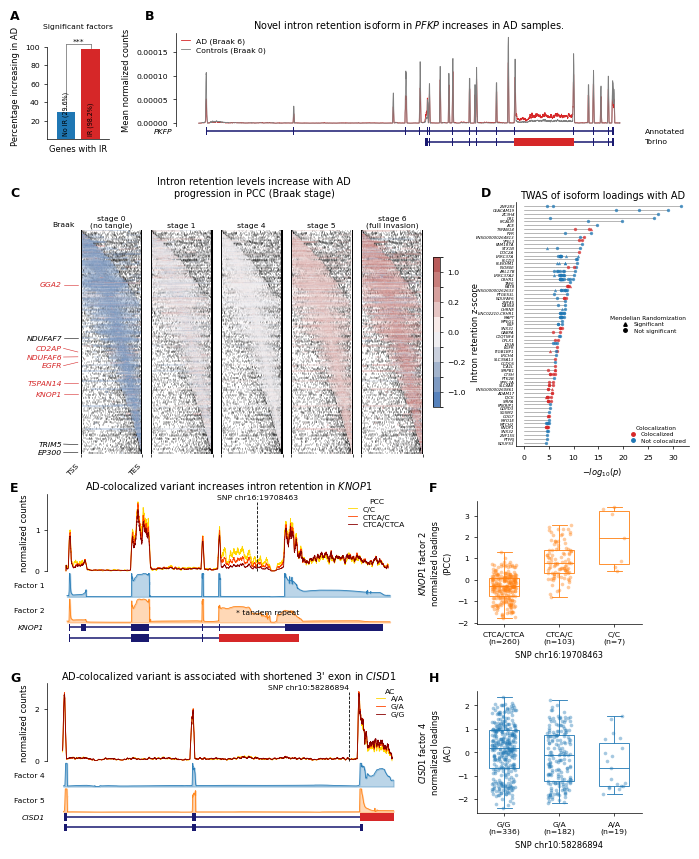

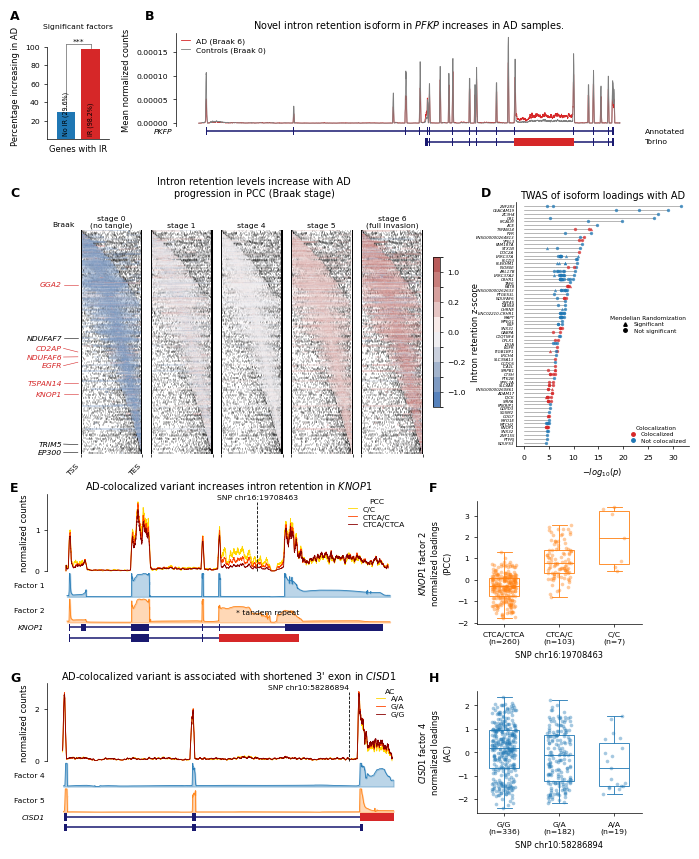

In [5]:
#: What each version of the page changes. Panels A, B and C are K=3 in both.
VERSIONS = {
    'default': dict(twas='twas_panel', knop1_k=5, pooled=False,
                    ir='ir_panel_k3'),
    # KNOP1 moves to the K=3 factorisation (matching A-D), CISD1 stays on K=5
    # because its event splits across two factors there, and the boxplots pool
    # the three tissues instead of showing one each.
    'k3': dict(twas='twas_panel_k3', knop1_k=3, pooled=True, ir='ir_panel_k3'),
    # ... and panel C's gene labels taken from the K=3 colocalisations too,
    # rather than the genome-wide K=5 table build_gene_label() used.
    'k3_corrected': dict(twas='twas_panel_k3', knop1_k=3, pooled=True,
                         ir='ir_panel_k3_colocK3'),
}


def build_figure(d=None, version='default', twas_key=None):
    """
    `version` selects the page:
      'default' — panel D from the ADgenes K=5 TWAS, KNOP1 and CISD1 both on
                  the K=5 factorisation, one tissue per boxplot
      'k3'      — panel D from the gao_k3 K=3 rerun, KNOP1 on K=3 (so A-E all
                  come from one run), CISD1 still K=5 and said so in its title,
                  and panels F and H pool AC + PCC + DLPFC with a per-tissue
                  marker and the genotype regression annotated

    `twas_key` is the old parameter and still selects panel D on its own.
    """
    if d is None:
        d = load_panels()
    cfg = dict(VERSIONS[version])
    if twas_key is not None:
        cfg['twas'] = twas_key

    fig = plt.figure(figsize=(PAGE_W / 25.4, PAGE_H / 25.4))

    # ---- A ---------------------------------------------------------------
    panel_letter(fig, 1.5, Y_ROW1 - 3.0, 'A')
    draw_beta_percentage(fig.add_axes(rect(A_X, Y_ROW1 + 3.0, A_W, A_H - 3.0)),
                         d['k3_beta_stats'])

    # ---- B ---------------------------------------------------------------
    panel_letter(fig, B_X - 8.0, Y_ROW1 - 3.0, 'B')
    draw_pkfp(fig, Y_ROW1 + 3.0, d['pkfp_panels']['PCC'])

    # ---- C ---------------------------------------------------------------
    panel_letter(fig, 1.5, Y_ROW2 - 4.0, 'C')
    draw_ir_progression(fig, Y_ROW2 + 2.0, d[cfg.get('ir', 'ir_panel_k3')])

    # ---- D ---------------------------------------------------------------
    panel_letter(fig, D_X - 9.0, Y_ROW2 - 4.0, 'D')
    draw_twas(fig.add_axes(rect(D_X, Y_ROW2, D_W, D_H)), d[cfg['twas']])

    # ---- E / F : KNOP1 in PCC -------------------------------------------
    panel_letter(fig, 1.5, Y_ROW3 - 3.0, 'E')
    k3 = cfg['knop1_k'] == 3
    draw_locus(fig, Y_ROW3, d['knop1_pcc']['coverage'],
               d['knop1_factors_k3'] if k3
               else d['factor_panels']['ENSG00000103550.factors'],
               KNOP1_K3 if k3 else KNOP1,
               'SNP chr16:19708463',
               'AD-colocalized variant increases intron retention in '
               '$\\it{KNOP1}$' + (' (K=3)' if k3 else ''),
               legend_loc='upper right', star=None if k3 else (0.52, 0.45),
               factor_colors=FACTOR_COLORS['ENSG00000103550.factors'],
               legend_title='PCC')

    panel_letter(fig, BOX_X - 12.0, Y_ROW3 - 3.0, 'F')
    ax_f = fig.add_axes(rect(BOX_X, Y_ROW3 + 2.0, BOX_W, BOX_H))
    if cfg['pooled']:
        draw_pooled_boxplot(
            ax_f, d['knop1_box_pooled_k3' if k3 else 'knop1_box_pooled_k5'],
            'ENSG00000103550.factor_2',
            f'$\\it{{KNOP1}}$ factor 2 (K={cfg["knop1_k"]})\n'
            f'normalized loadings\n(AC + PCC + DLPFC)',
            'SNP chr16:19708463', BOX_COLORS['F'],
            order=['CTCA/CTCA', 'CTCA/C', 'C/C'])
    else:
        draw_boxplot(ax_f, d['knop1_pcc']['boxplot'], 'ENSG00000103550.factor_2',
                     '$\\it{KNOP1}$ factor 2\nnormalized loadings\n(PCC)',
                     'SNP chr16:19708463', BOX_COLORS['F'],
                     order=['CTCA/CTCA', 'CTCA/C', 'C/C'])

    # ---- G / H : CISD1 in AC --------------------------------------------
    panel_letter(fig, 1.5, Y_ROW4 - 3.0, 'G')
    draw_locus(fig, Y_ROW4, d['coverage_panels']['ENSG00000122873.AC.coverage'],
               d['factor_panels']['ENSG00000122873.factors'], CISD1,
               'SNP chr10:58286894',
               "AD-colocalized variant is associated with shortened 3' exon "
               "in $\\it{CISD1}$" + (' (K=5)' if cfg['knop1_k'] == 3 else ''),
               legend_loc='upper right', snp_ha='right',
               factor_colors=FACTOR_COLORS['ENSG00000122873.factors'],
               legend_title='AC')

    panel_letter(fig, BOX_X - 12.0, Y_ROW4 - 3.0, 'H')
    ax_h = fig.add_axes(rect(BOX_X, Y_ROW4 + 2.0, BOX_W, BOX_H))
    if cfg['pooled']:
        draw_pooled_boxplot(
            ax_h, d['cisd1_box_pooled_k5'], 'ENSG00000122873.factor_4',
            '$\\it{CISD1}$ factor 4 (K=5)\nnormalized loadings\n'
            '(AC + PCC + DLPFC)',
            'SNP chr10:58286894', BOX_COLORS['H'], order=['G/G', 'G/A', 'A/A'])
    else:
        draw_boxplot(ax_h, d['boxplot_panels']['ENSG00000122873.AC.boxplot'],
                     'ENSG00000122873.factor_4',
                     '$\\it{CISD1}$ factor 4\nnormalized loadings\n(AC)',
                     'SNP chr10:58286894', BOX_COLORS['H'],
                     order=['G/G', 'G/A', 'A/A'])

    return fig


#: The standalone supplements: every factor of one model, with the pooled
#: genotype boxplot of each factor underneath. No coverage track.
SUPPLEMENTS = {
    'KNOP1_K5': dict(gene='ENSG00000103550', name='KNOP1', k=5,
                     factors='knop1_factors_k5_all', box='knop1_box_pooled_k5',
                     variant='chr16:19708463:CTCA:C',
                     order=['CTCA/CTCA', 'CTCA/C', 'C/C'],
                     transcripts=[f'ENSG00000103550.isoform_{i}'
                                  for i in range(1, 5)]),
    'CISD1_K3': dict(gene='ENSG00000122873', name='CISD1', k=3,
                     factors='cisd1_factors_k3_all', box='cisd1_box_pooled_k3',
                     variant='chr10:58286894:G:A',
                     order=['G/G', 'G/A', 'A/A'],
                     transcripts=[f'ENSG00000122873.isoform_{i}'
                                  for i in range(1, 3)]),
}


def build_supplement(key, d=None, page_w=180.0, track_h=11.0, irow_h=2.4,
                     box_w=36.0, box_h=32.0, hgap=18.0, vgap=20.0,
                     left=20.0, n_col=3, lm=False):
    """
    A supplementary page for one gene and one factorisation.

    Panel A is every factor of the model with the isoform models beneath it;
    then one panel per factor, each the pooled AC + PCC + DLPFC genotype
    boxplot of that factor with beta and the p-value of `factor ~ dosage`
    annotated. The main figure shows only the one or two factors that carry the
    event, so this is where the rest of the model can be checked.

    `left` is wide enough for the three-line y labels, and `vgap` leaves room
    under each boxplot for its two-line tick labels and x label.
    """
    cfg = SUPPLEMENTS[key]
    d = d or load_panels()
    fac, box = d[cfg['factors']], d[cfg['box']]
    factors = fac['factor_list']
    colours = ['tab:blue', 'tab:orange', 'tab:green', 'goldenrod', 'tab:red']
    n_f, n_t = len(factors), len(cfg['transcripts'])
    n_col = min(n_f, n_col)
    n_row = int(np.ceil(n_f / n_col))

    top_h = n_f * track_h + n_t * (irow_h + IROW_GAP)
    page_h = M_TOP + top_h + vgap + n_row * (box_h + vgap) + M_BOT
    fig = plt.figure(figsize=(page_w / 25.4, page_h / 25.4))

    def _rect(x, y, w, h):
        return [x / page_w, 1 - (y + h) / page_h, w / page_w, h / page_h]

    # ---- A: every factor, with the isoform models under them --------------
    panel_letter(fig, 1.5, M_TOP - 3.0, 'A', page_w, page_h)
    xc = fac['xlim_coords']
    xlim = (xc[0] - 1000, xc[-1] + 1000)
    trk_w = page_w - left - 8.0
    f_axes = [fig.add_axes(_rect(left, M_TOP + i * track_h, trk_w, track_h))
              for i in range(n_f)]
    # lm=False: the factor tracks are the raw smoothed factors. The lm
    # correction (Figure5_plot_helpers.factor_lm) divides each factor by a
    # line fitted along the gene when that line's slope runs with the strand,
    # to flatten 3' coverage decay. It reshapes the tracks, so it is off here.
    PH.plot_factors_wrapper(fac['EF_smooth'], fac['coords'], cfg['name'],
                            factor_list=factors, xlim=xlim, mute_y_axis=True,
                            ax=f_axes, strand=fac['strand'], lwidth=LW,
                            colores=colours[:n_f], lm=lm)
    for ax, f in zip(f_axes, factors):
        ax.set_xticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        ax.text(-0.008, 0.5, f'Factor {f.replace("factor", "")}',
                transform=ax.transAxes, fontsize=FS_ANNOT, ha='right', va='center')
    f_axes[0].set_title(f'$\\it{{{cfg["name"]}}}$ — all {n_f} factors of the '
                        f'K={cfg["k"]} factorisation, and each factor\'s '
                        f'loadings by genotype',
                        fontsize=FS_TITLE, pad=4)

    fc = [int(c.split(':')[1]) for c in fac['coords']]
    y0 = M_TOP + n_f * track_h
    i_axes = [fig.add_axes(_rect(left, y0 + i * (irow_h + IROW_GAP), trk_w, irow_h))
              for i in range(n_t)]
    draw_isoform_rows(i_axes, fac['iso'], cfg['transcripts'], fac['strand'],
                      (min(fc), max(fc)), xlim)
    i_axes[0].text(-0.008, 0.5, cfg['name'], transform=i_axes[0].transAxes,
                   fontsize=FS_ANNOT, ha='right', va='center', style='italic')

    # ---- B onwards: the pooled boxplot of each factor ---------------------
    # Each boxplot takes its factor's track colour, so panel B belongs to
    # Factor 1 and so on. The tissue key is drawn once, in the grid slot the
    # factors leave empty (or on the last panel when the grid is full).
    snp = cfg['variant'].rsplit(':', 2)[0]
    axes = []
    for i, f in enumerate(factors):
        col, row = i % n_col, i // n_col
        x = left + col * (box_w + hgap)
        y = M_TOP + top_h + vgap + row * (box_h + vgap)
        panel_letter(fig, x - 13.0, y - 3.0, chr(ord('B') + i),
                     page_w, page_h)
        n = f.replace('factor', '')
        axes.append(draw_pooled_boxplot(
            fig.add_axes(_rect(x, y, box_w, box_h)), box,
            f'{cfg["gene"]}.factor_{n}',
            f'$\\it{{{cfg["name"]}}}$ factor {n}\nnormalized loadings\n'
            f'(AC + PCC + DLPFC)',
            f'SNP {snp}', colours[i % len(colours)], order=cfg['order'],
            legend=False, reg_loc='above'))

    free = n_row * n_col - n_f
    if free:
        col, row = n_f % n_col, n_f // n_col
        lx = left + col * (box_w + hgap)
        ly = M_TOP + top_h + vgap + row * (box_h + vgap)
        lax = fig.add_axes(_rect(lx, ly, box_w, box_h))
        lax.axis('off')
        lax.legend(handles=axes[0].tissue_handles_, title='tissue (n samples)',
                   frameon=False, fontsize=FS_LAB, title_fontsize=FS_LAB,
                   loc='upper left', handletextpad=0.5, labelspacing=0.5)
    else:
        axes[-1].legend(handles=axes[-1].tissue_handles_, frameon=False,
                        fontsize=FS_ANNOT, loc='lower right', handletextpad=0.3,
                        borderpad=0.1, labelspacing=0.2)
    return fig


#: The two figures marked `# SAVE THIS FIGURE` in Figure5_examples. Both are on
#: the K=3 by-AD tree; CISD1 uses factor 2, which is the long 3' form there (its
#: K=5 factor 4 has no single K=3 counterpart).
BY_AD_SUPPLEMENTS = {
    'KNOP1_byAD': dict(name='KNOP1', key='knop1_byad_pooled_k3',
                       factor='ENSG00000103550.factor_2',
                       order=('CTCA/CTCA', 'CTCA/C', 'C/C'),
                       variant='chr16:19708463:CTCA:C', legend_loc='best'),
    'CISD1_byAD': dict(name='CISD1', key='cisd1_byad_pooled_k3',
                       factor='ENSG00000122873.factor_2',
                       order=('G/G', 'G/A', 'A/A'),
                       variant='chr10:58286894:G:A', legend_loc='best'),
}


def build_by_ad_supplement(key='KNOP1_byAD', d=None, figsize=(6.6, 2.9)):
    """
    One of the figures marked `# SAVE THIS FIGURE` in Figure5_examples: the
    pooled AC + PCC + DLPFC loadings split by AD status, with the genotype
    regression fitted within each group and tissue as a covariate.

    Drawn by Figure5_examples.plot_by_ad_boxplot, so it is the same code the
    exploratory notebook uses — only the data comes from a pickle here.
    """
    cfg = BY_AD_SUPPLEMENTS[key]
    d = d or load_panels()
    n = cfg['factor'].split('.')[-1].replace('_', ' ')
    axes = EX.plot_by_ad_boxplot(
        d[cfg['key']], cfg['factor'], order=list(cfg['order']), figsize=figsize,
        regression=True, reg_covariates=['tissue'],
        legend_loc=cfg['legend_loc'],
        ylabel=f'$\\it{{{cfg["name"]}}}$ {n}\n'
               f'normalized loadings\n(AC + PCC + DLPFC)',
        xlabel=f'SNP {cfg["variant"].rsplit(":", 2)[0]}')
    return axes[0].figure


def save(fig, stem):
    """PNG, PDF and SVG of one figure. The SVG is the Inkscape-editable one."""
    fig.savefig(os.path.join(FIG5_DIR, f'{stem}.png'), dpi=400)
    fig.savefig(os.path.join(FIG5_DIR, f'{stem}.pdf'))
    fig.savefig(os.path.join(FIG5_DIR, f'{stem}.svg'))
    return fig


def render(version, stem, d=None):
    """Draw one version of the figure and write its PNG, PDF and SVG."""
    return save(build_figure(d=d, version=version), stem)


def render_supplement(key, d=None, stem=None):
    """Draw one supplementary page and write it under its own name."""
    return save(build_supplement(key, d=d), stem or f'Figure5_supp_{key}')

fig = render('default', 'Figure5_publication')
print(f'page: {PAGE_W:.1f} x {PAGE_H:.1f} mm')
fig

## Alternative version: K=3 TWAS

Panels A, B and C are built from the K=3 (`gao_k3`) run, while panel D above
is the ADgenes K=5 TWAS. This cell redraws the same page with panel D taken
from `TWAS_summary_K3` — the K=3 rerun of the TWAS, MR and colocalisation
analysis — so that A–D all come from one run. Saved as
`Figure5_publication_K3.png` / `.pdf`.

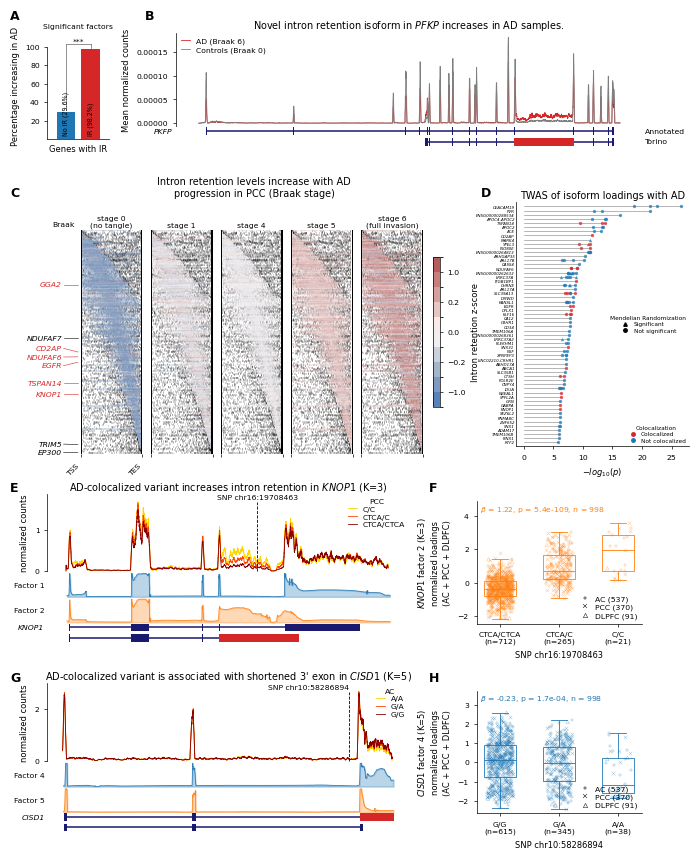

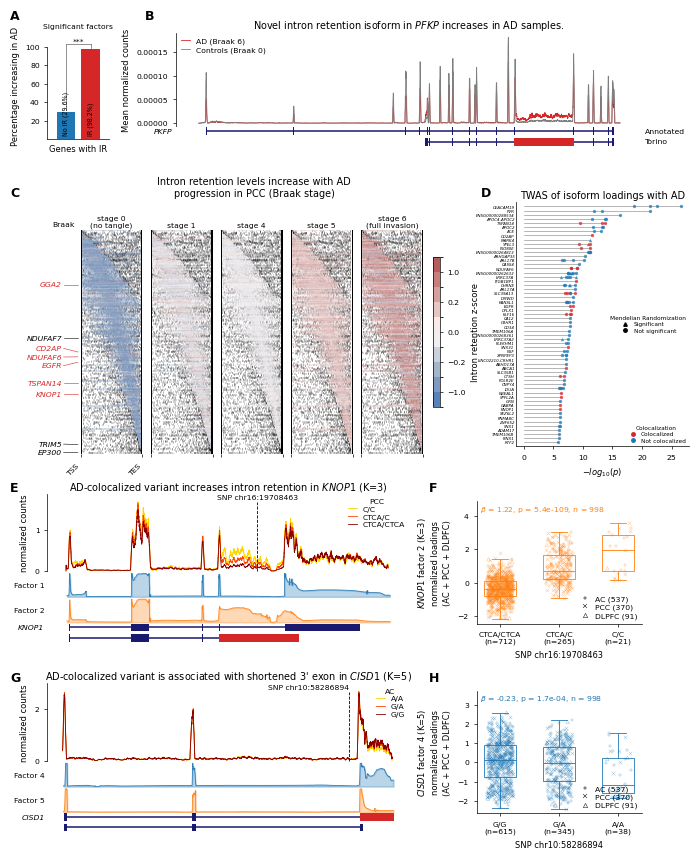

In [6]:
# The alternative version of the figure: panel D from the gao_k3 TWAS rerun
# (TWAS_summary_K3) instead of the ADgenes tables. That is the same K=3 run the
# data behind panels A, B and C comes from, so this version is internally
# consistent across A-D; everything else on the page is unchanged.
if _IS_MAIN:
    fig_k3 = render('k3', 'Figure5_publication_K3')
fig_k3 if _IS_MAIN else None

## Supplementary: every factor of a model

Standalone pages with their own saves. Panel A is all the factors of one
factorisation with the isoform models beneath; then one pooled genotype
boxplot per factor, each annotated with beta and p of `factor ~ allele dosage`.

**KNOP1 on K=5** — the model the main figure no longer uses for this gene.

saved Figure5_supp_KNOP1_K5


saved Figure5_supp_CISD1_K3


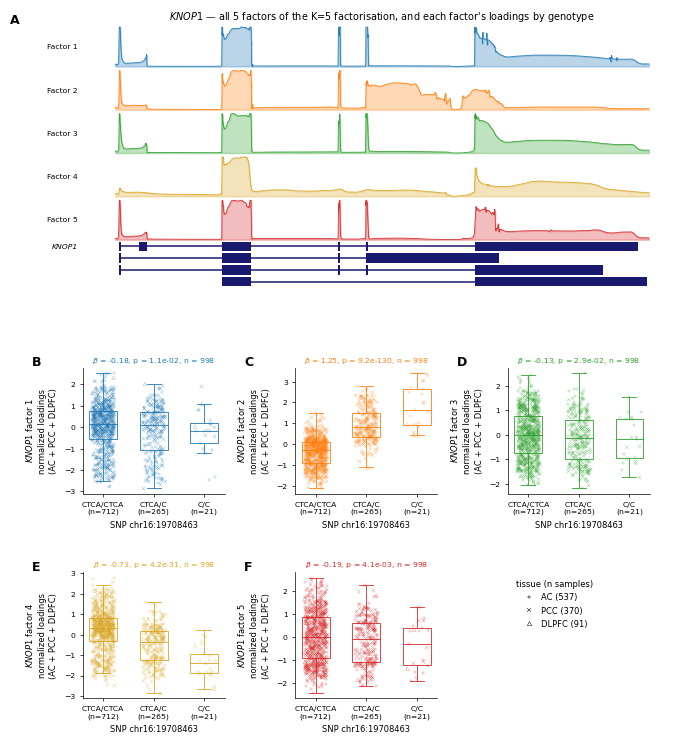

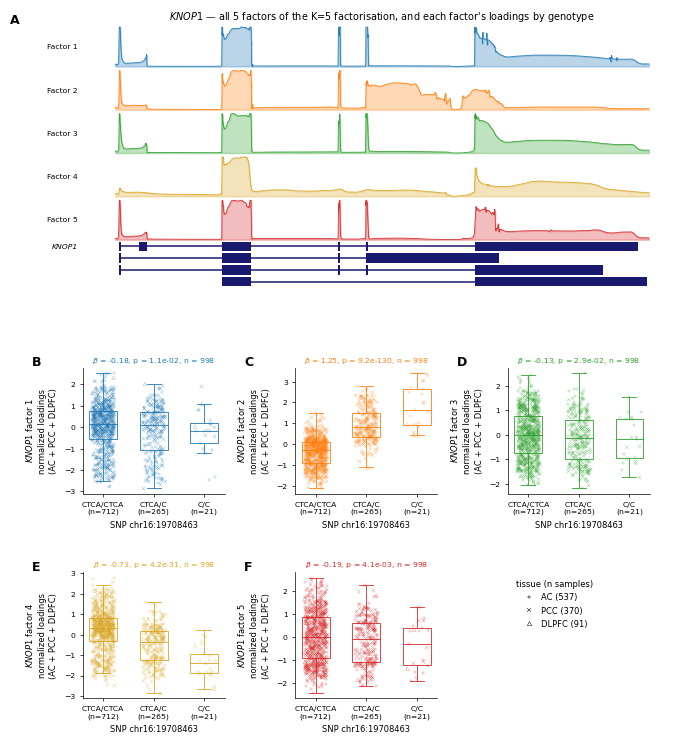

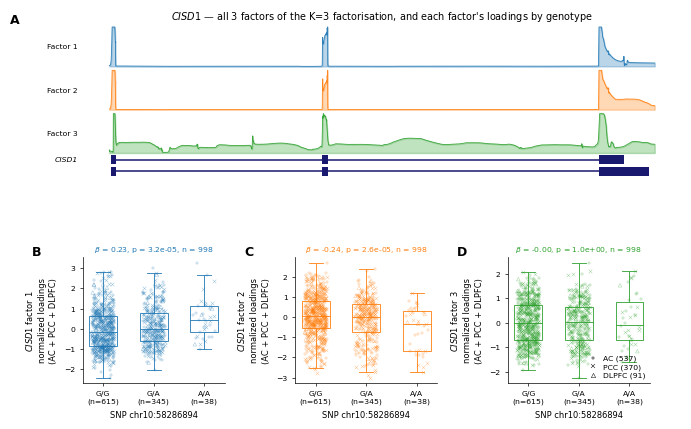

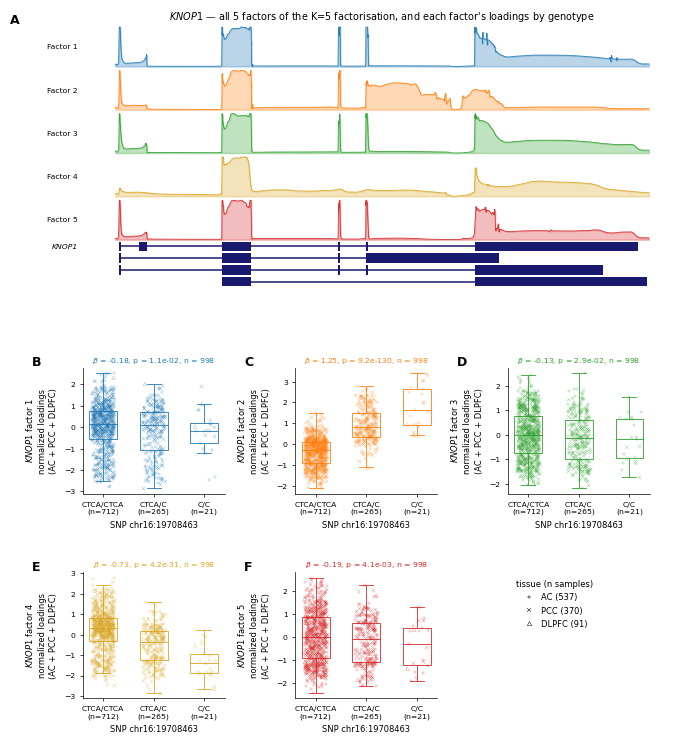

In [7]:
# Supplementary: every factor of one model, with each factor's pooled genotype
# boxplot underneath. These are standalone pages with their own saves — the main
# figure shows only the one or two factors that carry the event, so this is
# where the rest of each model can be checked.
#
#   KNOP1_K5  the K=5 model the main figure no longer uses for KNOP1
#   CISD1_K3  the K=3 model CISD1 is not drawn on
if _IS_MAIN:
    _d = load_panels()
    for _key in SUPPLEMENTS:
        render_supplement(_key, _d)
        print('saved Figure5_supp_' + _key)
    fig_supp_knop1 = build_supplement('KNOP1_K5', _d)
fig_supp_knop1 if _IS_MAIN else None

**CISD1 on K=3** — the model CISD1 is *not* drawn on in the main figure.

Its event splits across factor 1 (up with A) and factor 2 (down with A) here,
which is why the main figure keeps CISD1 on K=5 where it sits on one factor.

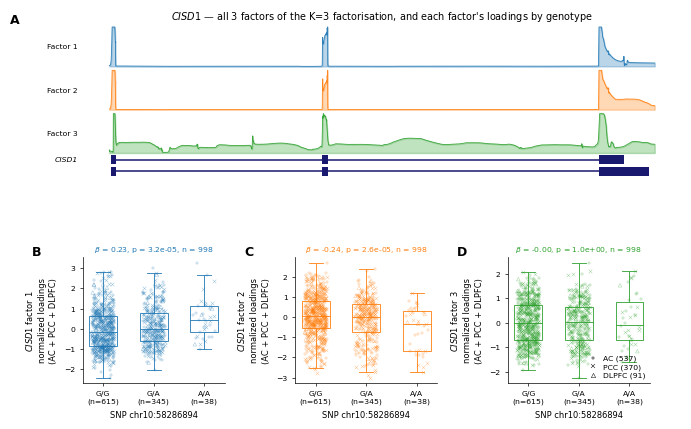

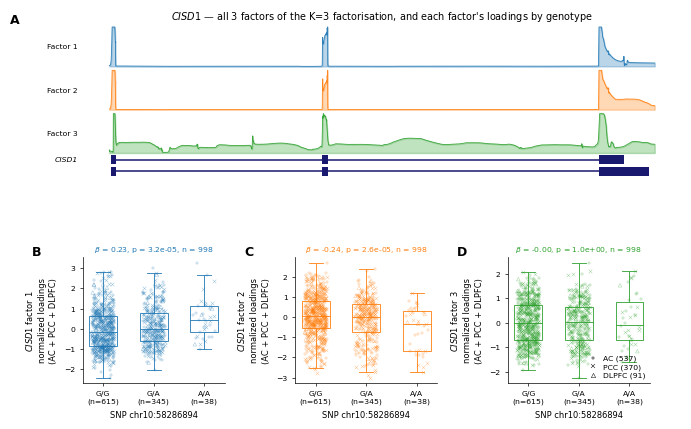

In [8]:
if _IS_MAIN:
    fig_supp_cisd1 = build_supplement('CISD1_K3', _d)
fig_supp_cisd1 if _IS_MAIN else None

## Supplementary: pooled loadings split by AD status

The figure marked `# SAVE THIS FIGURE` in `Figure5_examples.ipynb`, drawn by the
same function — only the data comes from a pickle here.

saved Figure5_supp_KNOP1_byAD


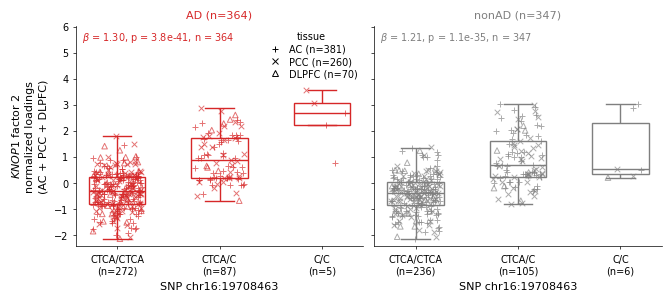

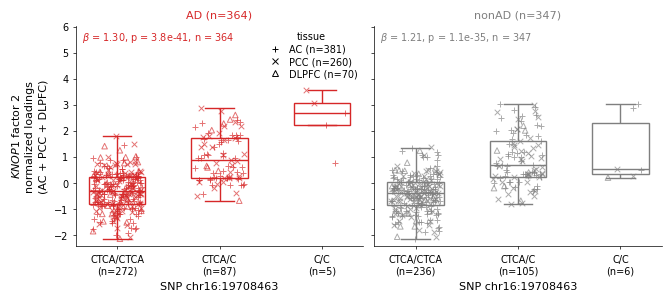

In [9]:
# Supplementary: the figure marked `# SAVE THIS FIGURE` in Figure5_examples —
# the pooled AC + PCC + DLPFC loadings split by AD status, with the genotype
# regression fitted within each group and tissue as a covariate.
if _IS_MAIN:
    fig_supp_byad = save(build_by_ad_supplement('KNOP1_byAD', _d),
                         'Figure5_supp_KNOP1_byAD')
    print('saved Figure5_supp_KNOP1_byAD')
fig_supp_byad if _IS_MAIN else None

**CISD1** — the second marked figure. On the K=3 tree its event sits on
factor 2 (the long 3' form), so the shortening allele lowers the loading;
there is no single K=3 counterpart to the K=5 factor 4 the main figure uses.

saved Figure5_supp_CISD1_byAD


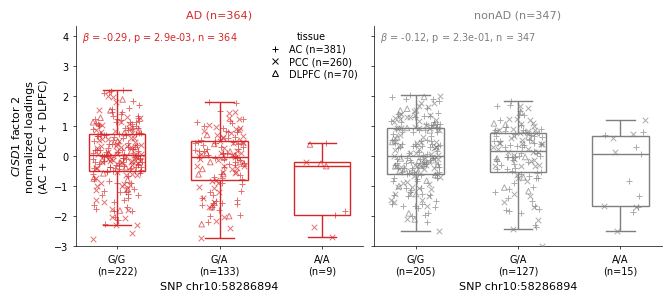

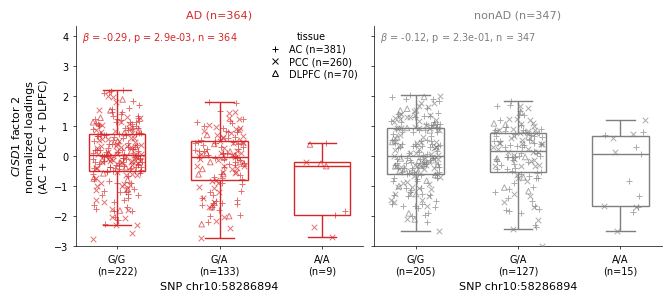

In [10]:
# The second marked figure. CISD1 uses factor 2 here — on the K=3 tree that is
# the long 3' form, and the allele that shortens it lowers the loading.
if _IS_MAIN:
    fig_supp_byad_cisd1 = save(build_by_ad_supplement('CISD1_byAD', _d),
                               'Figure5_supp_CISD1_byAD')
    print('saved Figure5_supp_CISD1_byAD')
fig_supp_byad_cisd1 if _IS_MAIN else None

## Render

180 x 220.4 mm — inside the Nature Genetics 240 mm height limit.